In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
f1_score, roc_auc_score, confusion_matrix,
classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
import joblib

In [4]:
df = pd.read_csv("Titanic-Dataset (1).csv")
print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch Embarked            Ticket     Fare Cabin  PassengerId  Pclass  \
0      0        S         A/5 21171   7.2500   NaN            1       3   
1      0        C          PC 17599  71.2833   C85            2       1   
2      0        S  STON/O2. 3101282   7.9250   NaN            3       3   
3      0        S            113803  53.1000  C123            4       1   
4      0        S            373450   8.0500   NaN            5       3   

   Survived  
0         0  
1         1  
2         1  
3         1  
4         0  
(8

Survived
0    549
1    342
Name: count, dtype: int64


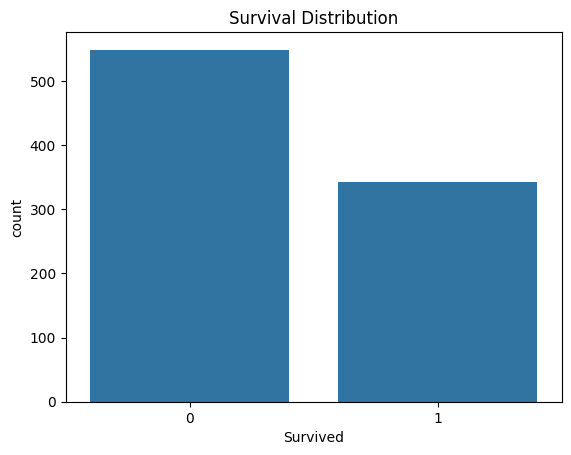

In [5]:
print(df["Survived"].value_counts())
sns.countplot(data=df, x="Survived")
plt.title("Survival Distribution")
plt.show()

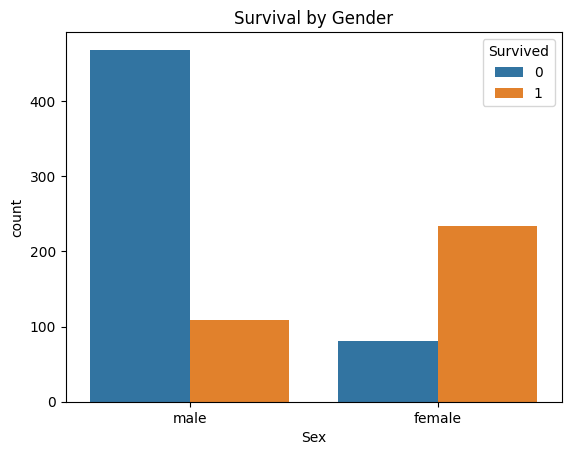

In [6]:
sns.countplot(data=df, x="Sex", hue="Survived")
plt.title("Survival by Gender")
plt.show()

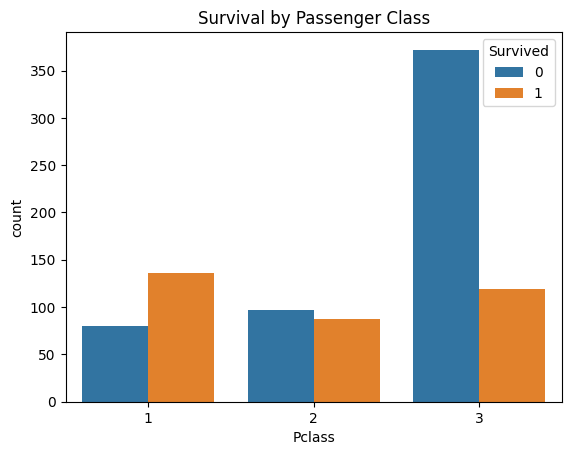

In [7]:
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survival by Passenger Class")
plt.show()

In [8]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = df[features]
y = df["Survived"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.20, random_state=42, stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (712, 7)
Testing data: (179, 7)


In [11]:
numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]
numeric_transformer = Pipeline([
 ("imputer", SimpleImputer(strategy="median")),
 ("scaler", StandardScaler())
 ])
categorical_transformer = Pipeline([
 ("imputer", SimpleImputer(strategy="most_frequent")),
 ("encoder", OneHotEncoder(handle_unknown="ignore"))
 ])
preprocessor = ColumnTransformer([
 ("num", numeric_transformer, numeric_features),
 ("cat", categorical_transformer, categorical_features)
 ])

In [12]:
logistic_model = Pipeline([
 ("preprocessor", preprocessor),
 ("model", LogisticRegression(max_iter=1000))
 ])

In [13]:
decision_tree = Pipeline([
 ("preprocessor", preprocessor),
 ("model", DecisionTreeClassifier(random_state=42, max_depth=5))
 ])

In [14]:
random_forest = Pipeline([
 ("preprocessor", preprocessor),
 ("model", RandomForestClassifier(n_estimators=300, random_state=42))
 ])

In [15]:
gradient_boosting = Pipeline([
 ("preprocessor", preprocessor),
 ("model", GradientBoostingClassifier(random_state=42))
 ])

In [16]:
xgb_model = Pipeline([
 ("preprocessor", preprocessor),
 ("model", XGBClassifier(
 n_estimators=300, max_depth=4, learning_rate=0.05,
 subsample=0.8, colsample_bytree=0.8,
 eval_metric="logloss", random_state=42))
 ])

In [17]:
ml_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_boosting,
    "XGBoost": xgb_model
}

In [18]:
ml_results = []

for name, model in ml_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    ml_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

ml_results_df = pd.DataFrame(ml_results)
print(ml_results_df)

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.804469   0.793103  0.666667  0.724409  0.843742
1        Decision Tree  0.765363   0.754717  0.579710  0.655738  0.797101
2        Random Forest  0.810056   0.796610  0.681159  0.734375  0.828722
3    Gradient Boosting  0.798883   0.789474  0.652174  0.714286  0.817918
4              XGBoost  0.782123   0.750000  0.652174  0.697674  0.819038


In [19]:
print(ml_results_df.sort_values(by="F1 Score", ascending=False))

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
2        Random Forest  0.810056   0.796610  0.681159  0.734375  0.828722
0  Logistic Regression  0.804469   0.793103  0.666667  0.724409  0.843742
3    Gradient Boosting  0.798883   0.789474  0.652174  0.714286  0.817918
4              XGBoost  0.782123   0.750000  0.652174  0.697674  0.819038
1        Decision Tree  0.765363   0.754717  0.579710  0.655738  0.797101


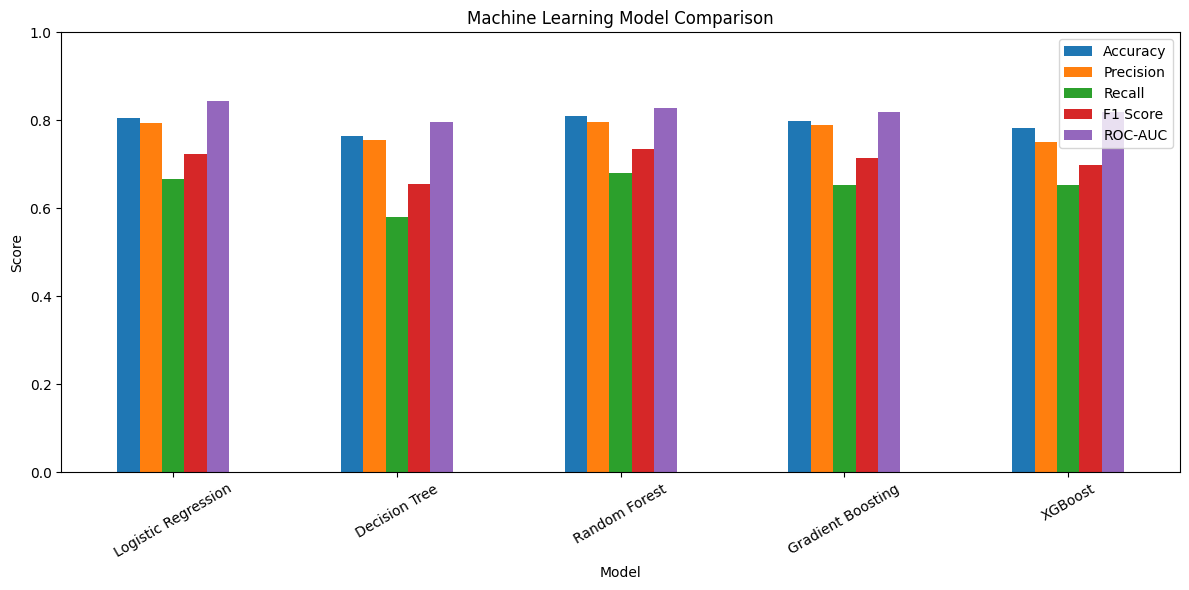

In [20]:
ml_results_df.set_index("Model")[
["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
 ].plot(kind="bar", figsize=(12, 6))
plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()